In [ ]:
####################################################
####################################################
## test the keypoint_moseq with SLEAP output 
## original notebook from https://keypoint-moseq.readthedocs.io/en/stable/modeling.html
####################################################
####################################################

In [286]:
import keypoint_moseq as kpms
import matplotlib.pyplot as plt

In [287]:
project_dir = "/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test"
#project_dir = "/Users/jingkui.wang/workspace/imp/image_analysis_test/results/videos_sleap_test"

config = lambda: kpms.load_config(project_dir)

kpms.check_installation(notebook_version="0.8")

keypoint-MoSeq installation check
  Python 3.12.16 (/Users/jingkui.wang/miniforge3/envs/keypoint_moseq/bin/python)
  keypoint-moseq   0.8.4     /Users/jingkui.wang/miniforge3/envs/keypoint_moseq/lib/python3.12/site-packages/keypoint_moseq
  jax-moseq        0.3.8     /Users/jingkui.wang/miniforge3/envs/keypoint_moseq/lib/python3.12/site-packages/jax_moseq
  jax              0.12.0.1  /Users/jingkui.wang/miniforge3/envs/keypoint_moseq/lib/python3.12/site-packages/jax
  jaxlib           0.12.0.1  /Users/jingkui.wang/miniforge3/envs/keypoint_moseq/lib/python3.12/site-packages/jaxlib
  JAX CUDA plugin  not installed
  Devices: cpu:0 (cpu)
  JAX is using the CPU. For GPU support (Linux only), install keypoint-moseq[cuda] and use a machine with a GPU.
  Notebook: written for 0.8, as installed


In [299]:
## setup for SLEAP
sleap_file = "/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/labels.v003_245frames.labeled_trained.slp"  # any .slp or .h5 file with predictions for a single video
kpms.setup_project(project_dir, sleap_file=sleap_file)

The directory `/Volumes/groups/tanaka/People/current/jiwang/projects/i
mage_analysis/Deniz_video_sleap/sleap_test/kpms_test` already exists.
Use `overwrite=True` or pick a different name


In [300]:
## Edit the config file
kpms.update_config(
    project_dir,
    video_dir="/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/",
    anterior_bodyparts=["nose"],
    posterior_bodyparts=["tail_tip"],
    use_bodyparts=["nose", "eyeL", "eyeR", "head", "torso", "tail_base", "tail_2", "tail_3", "tail_tip"],
    fps=30,
)

In [301]:
# load data (e.g. from SLEAP)
keypoint_data_path = "/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/labels.v003_245frames.labeled_trained.slp"  # can be a file, a directory, or a list of files
coordinates, confidences, bodyparts = kpms.load_keypoints(keypoint_data_path, "sleap")

Loading keypoints: 100%|██████████████████| 1/1 [00:00<00:00,  6.00it/s]


In [302]:
#video_paths = {
#    "labels.v003_245frames.labeled_trained": (
#        "/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/EXP009_A2-IR_260910_6x.mp4"
#    )
#}
#check_config = config().copy()
#check_config["video_paths"] = video_paths

In [303]:
coordinates
confidences
bodyparts

['nose',
 'eyeL',
 'eyeR',
 'head',
 'torso',
 'tail_base',
 'tail_2',
 'tail_3',
 'tail_tip']

In [304]:
## check videos
kpms.check_videos(coordinates, print_table=True, **config())

Checking videos: 100%|████████████████████| 1/1 [00:00<00:00,  9.19it/s]

Videos matched to 1 of 1 recordings:
  labels.v003_245frames.labeled_trained
    /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/labels.v003_245frames.labeled_trained.mp4  (3,784 frames, 600 x 600)


{'labels.v003_245frames.labeled_trained': '/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/labels.v003_245frames.labeled_trained.mp4'}

In [305]:
data, metadata = kpms.format_data(coordinates, confidences, **config())

Loading sample frames: 100%|███████████| 40/40 [00:00<00:00, 186.41it/s]


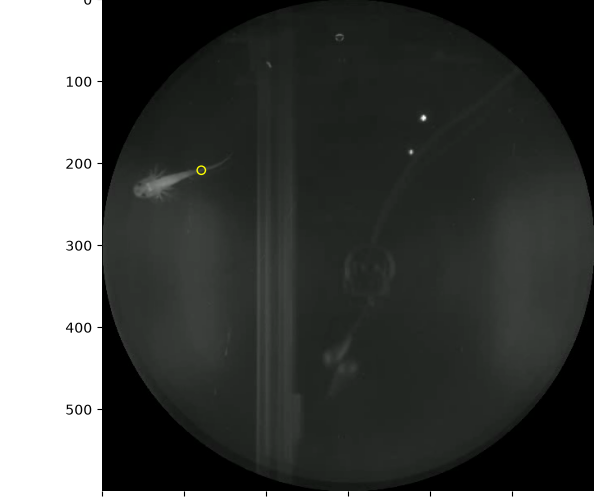

In [306]:
%matplotlib widget
kpms.noise_calibration(project_dir, coordinates, confidences, **config())

>=90.0% of variance explained by 3 components.


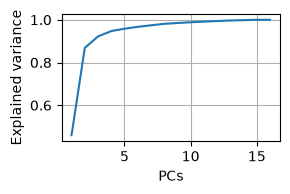

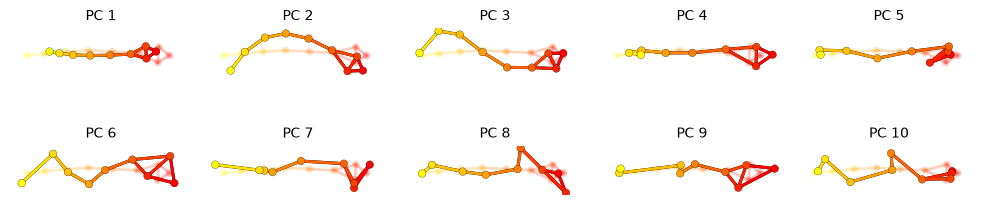

In [318]:
plt.close("all")
%matplotlib inline
pca = kpms.fit_pca(**data, **config())
kpms.save_pca(pca, project_dir)

kpms.print_dims_to_explain_variance(pca, 0.9)
kpms.plot_scree(pca, project_dir=project_dir)
kpms.plot_pcs(pca, project_dir=project_dir, **config())

# use the following to load an already fit model
# pca = kpms.load_pca(project_dir)


In [269]:
kpms.update_config(project_dir, latent_dim=10)

In [319]:
## Estimating Hyperparameters
kpms.update_config(
    project_dir,
    sigmasq_loc=kpms.estimate_sigmasq_loc(data["Y"], data["mask"], filter_size=config()["fps"])
)

In [320]:
# initialize the model
model = kpms.init_model(data, metadata=metadata, pca=pca, **config())

In [321]:
# optionally modify kappa
#model = kpms.update_hypparams(model, kappa=)

In [322]:
kappa = 1000
decrease_kappa_factor = 10
num_ar_iters = 50
num_full_iters = 300
print(kappa)

1000


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11
_03-16_20_04


 47%|████████████████▍                  | 24/51 [00:01<00:01, 14.45it/s]

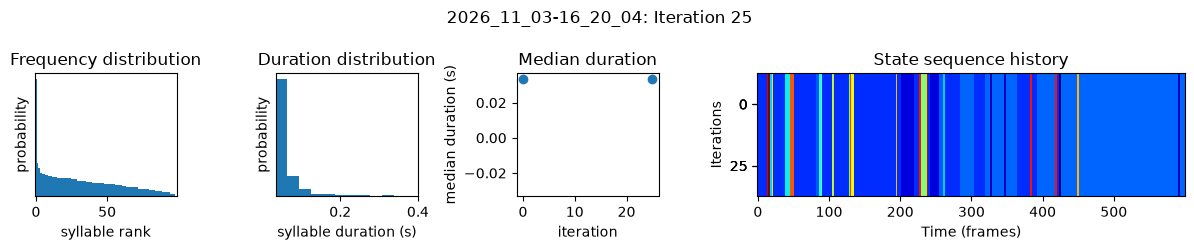

 98%|██████████████████████████████████▎| 50/51 [00:03<00:00, 14.39it/s]

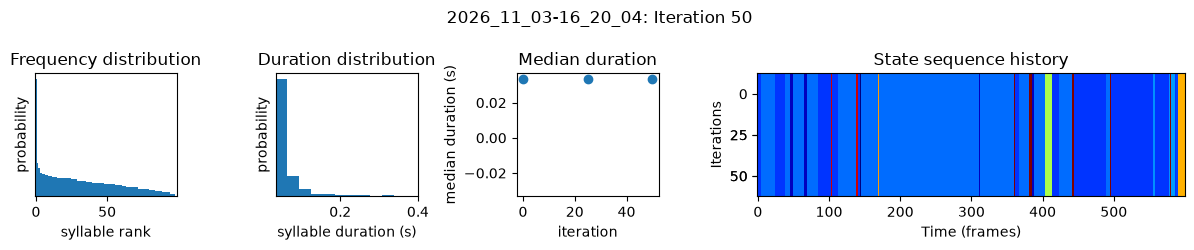

100%|███████████████████████████████████| 51/51 [00:04<00:00, 11.74it/s]
'kappa' with <class 'int'> will be cast to <class 'float'>

Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11
_03-16_20_04


 98%|██████████████████████████████████▎| 50/51 [00:03<00:00, 14.57it/s]

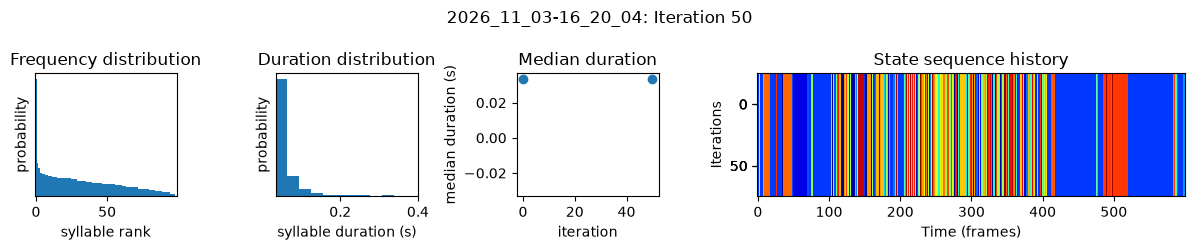

100%|███████████████████████████████████| 51/51 [00:04<00:00, 12.74it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11
_03-16_20_04


  8%|██▊                               | 25/301 [00:07<01:27,  3.17it/s]

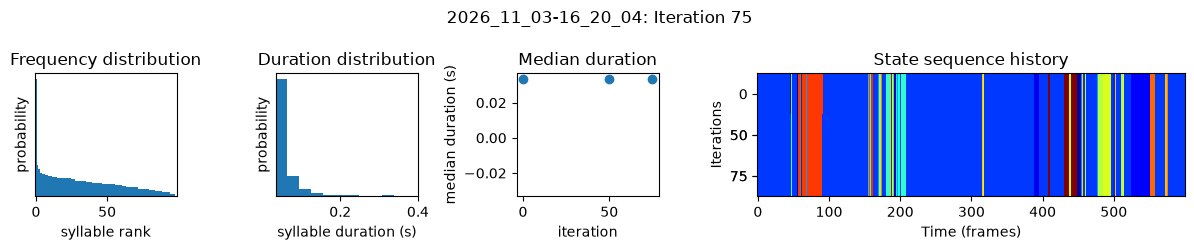

 17%|█████▋                            | 50/301 [00:16<01:17,  3.24it/s]

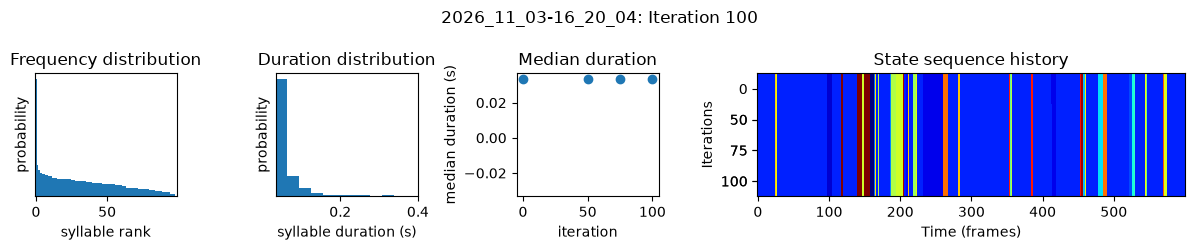

 25%|████████▍                         | 75/301 [00:24<01:11,  3.17it/s]

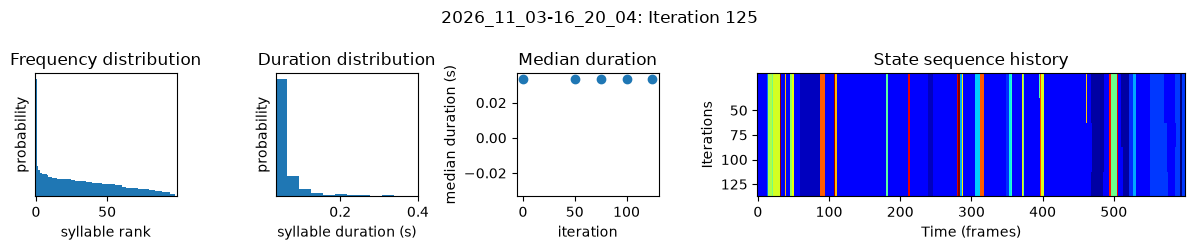

 33%|██████████▉                      | 100/301 [00:33<01:03,  3.19it/s]

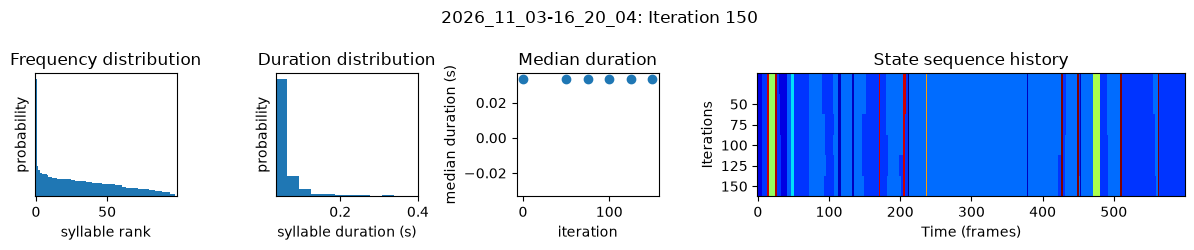

 42%|█████████████▋                   | 125/301 [00:41<00:55,  3.19it/s]

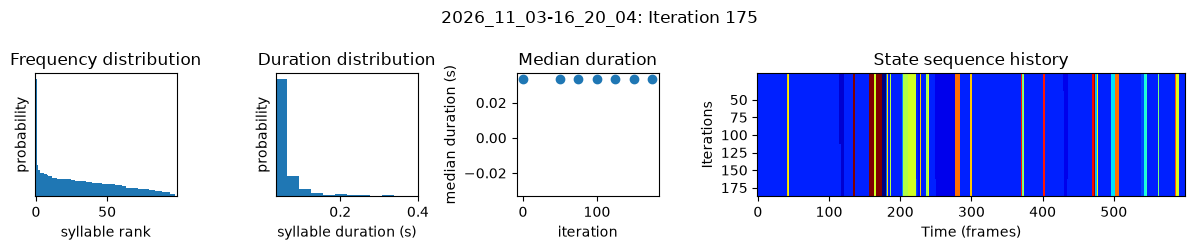

 50%|████████████████▍                | 150/301 [00:49<00:46,  3.22it/s]

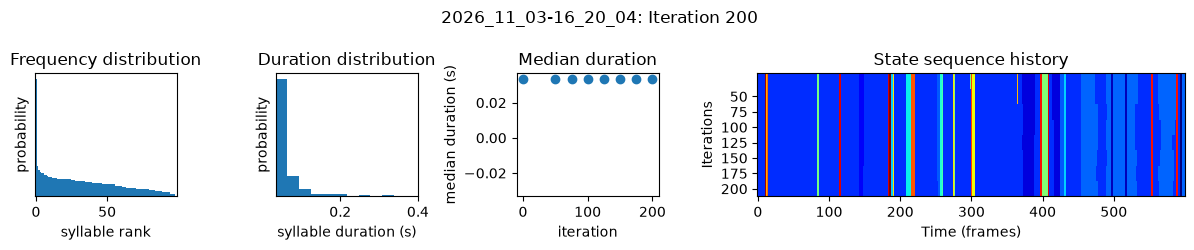

 58%|███████████████████▏             | 175/301 [00:58<00:39,  3.23it/s]

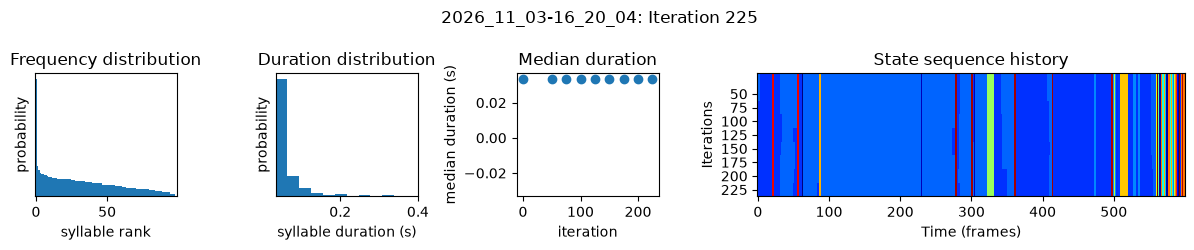

 66%|█████████████████████▉           | 200/301 [01:06<00:31,  3.22it/s]

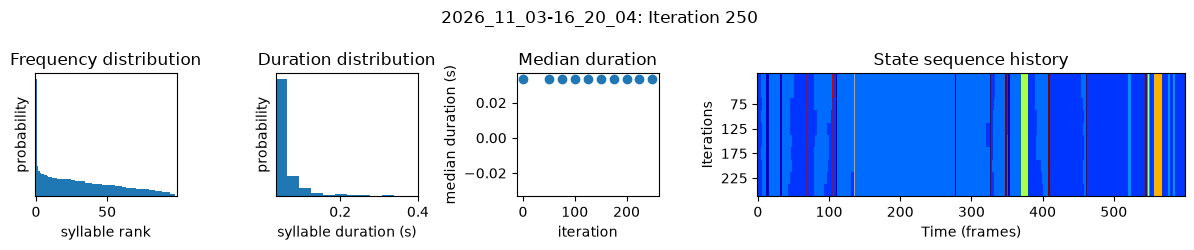

 75%|████████████████████████▋        | 225/301 [01:14<00:23,  3.21it/s]

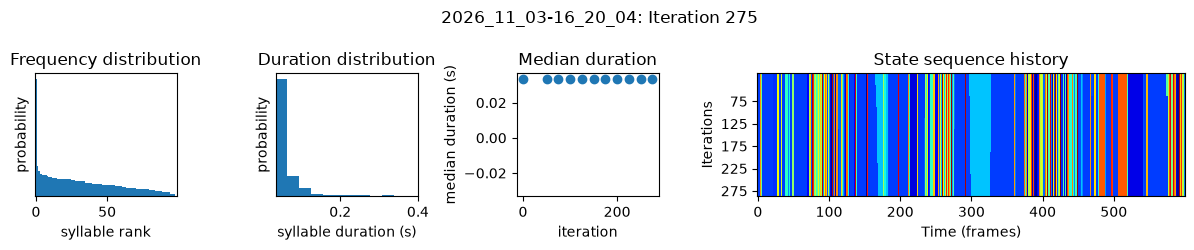

 83%|███████████████████████████▍     | 250/301 [01:22<00:15,  3.25it/s]

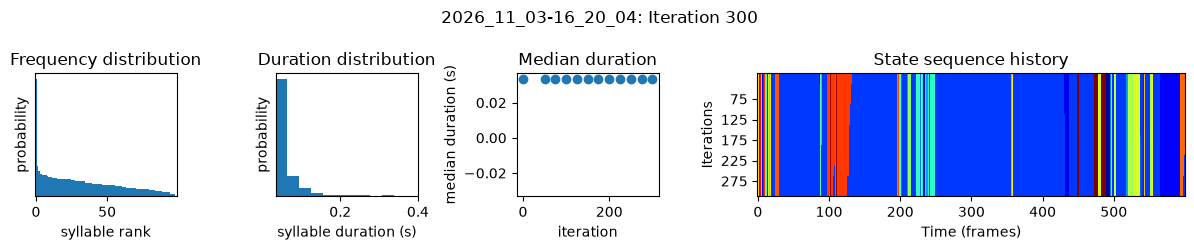

 91%|██████████████████████████████▏  | 275/301 [01:31<00:08,  3.23it/s]

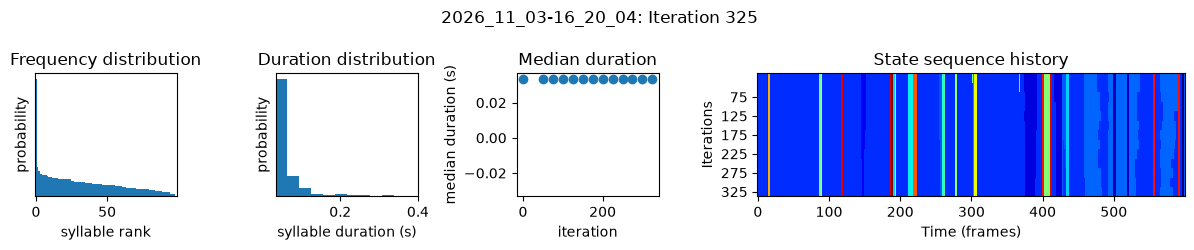

100%|████████████████████████████████▉| 300/301 [01:39<00:00,  3.22it/s]

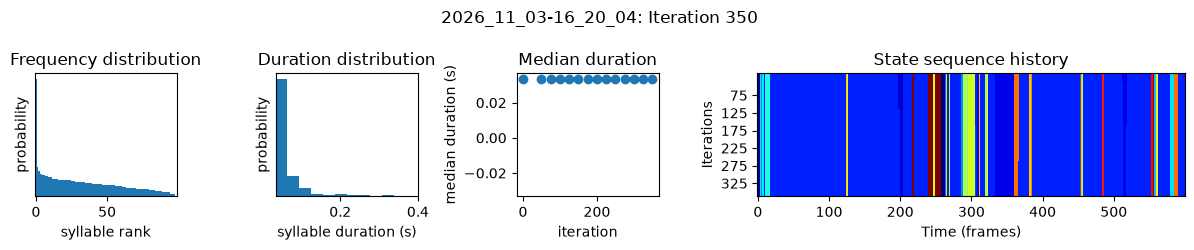

100%|█████████████████████████████████| 301/301 [01:40<00:00,  3.00it/s]


In [276]:
## Fitting an AR-HMM
model, model_name = kpms.fit_model(
    model, data, metadata, project_dir, ar_only=True, num_iters=num_ar_iters, **config()
)

## Fitting the full model
# load model checkpoint
model, data, metadata, current_iter = kpms.load_checkpoint(
    project_dir, model_name, iteration=num_ar_iters
)

# modify kappa to maintain the desired syllable time-scale
#model = kpms.update_hypparams(model, kappa=1e2)
model = kpms.update_hypparams(model, kappa=kappa)
model = kpms.fit_model(
        model,
        data,
        metadata,
        project_dir,
        model_name,
        ar_only=True,
        num_iters=num_ar_iters,
        save_every_n_iters=50,
        **config()
    )[0];

# stage 2: fit the full model
model = kpms.update_hypparams(model, kappa=kappa/decrease_kappa_factor)

# run fitting for an additional 500 iters
model = kpms.fit_model(
    model,
    data,
    metadata,
    project_dir,
    model_name,
    ar_only=False,
    start_iter=current_iter,
    num_iters=current_iter + num_full_iters,
    **config(),
)[0]

In [277]:
## Sort syllables by frequency
# modify a saved checkpoint so syllables are ordered by frequency
kpms.reindex_syllables_in_checkpoint(project_dir, model_name);

Reindexing: 100%|███████████| 14/14 [00:01<00:00,  7.73model snapshot/s]


In [278]:
# load the most recent model checkpoint
#model, data, metadata, current_iter = kpms.load_checkpoint(project_dir, model_name)

# extract results
results = kpms.extract_results(model, metadata, project_dir, model_name, overwrite=True)

Saved results to /Volumes/groups/tanaka/People/current/jiwang/projects
/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11_03-
16_20_04/results.h5


In [279]:
# optionally save results as csv
kpms.save_results_as_csv(results, project_dir, model_name)

Saving to csv: 100%|██████████████████████| 1/1 [00:00<00:00,  8.93it/s]


In [280]:
results = kpms.load_results(project_dir, model_name)


(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Frequency distribution'}, xlabel='syllable rank', ylabel='probability'>)

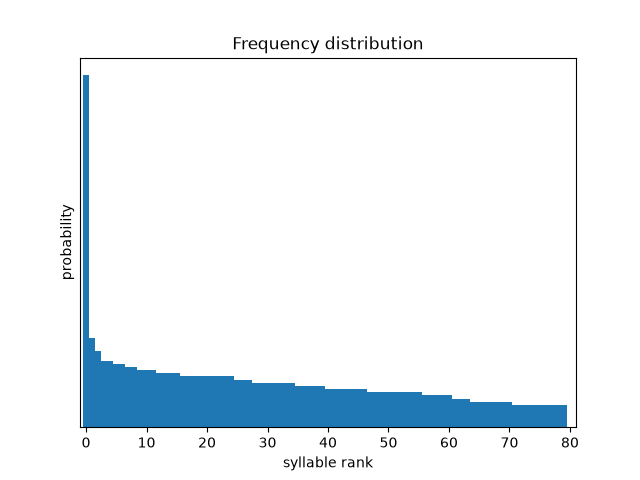

In [315]:
kpms.plot_syllable_frequencies(project_dir, model_name, results, minlength = 10, min_frequency = 0.005)

In [282]:
#kpms.plot_duration_distribution(project_dir, model_name, results, num_bins = 50)

In [316]:
coordinates
results
#project_dir
#model_name

{'labels.v003_245frames.labeled_trained': {'centroid': array([[248.24041029, 170.38151376],
         [247.31876549, 168.84055325],
         [247.01648935, 168.29586742],
         ...,
         [412.38268528,  90.8266792 ],
         [411.8686986 ,  90.97107326],
         [411.31343753,  90.13200375]], shape=(3784, 2)),
  'heading': array([ 2.72720307,  2.55736297,  2.51433945, ..., -0.91194529,
         -0.89820856, -0.90596087], shape=(3784,)),
  'latent_state': array([[-2.64931547,  1.12753723,  5.06130552, ...,  1.1650556 ,
          -0.15524615,  1.07333976],
         [ 0.67693957, -0.69747731,  2.351781  , ...,  0.48926956,
           0.88144569,  1.43171672],
         [-0.48455883, -0.82504702, -0.01696364, ..., -2.40423478,
           0.83882726, -0.10900553],
         ...,
         [-0.11300643, -1.2710693 ,  0.23592994, ..., -0.32123143,
          -0.08443704,  0.07256541],
         [-0.04366603, -1.11941708,  0.71012206, ..., -0.97969921,
          -0.91566604,  0.25393057],
 

Saving trajectory plots to /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11_03-16_20_04/trajectory_plots


Generating trajectory plots: 100%|██████| 46/46 [00:14<00:00,  3.27it/s]


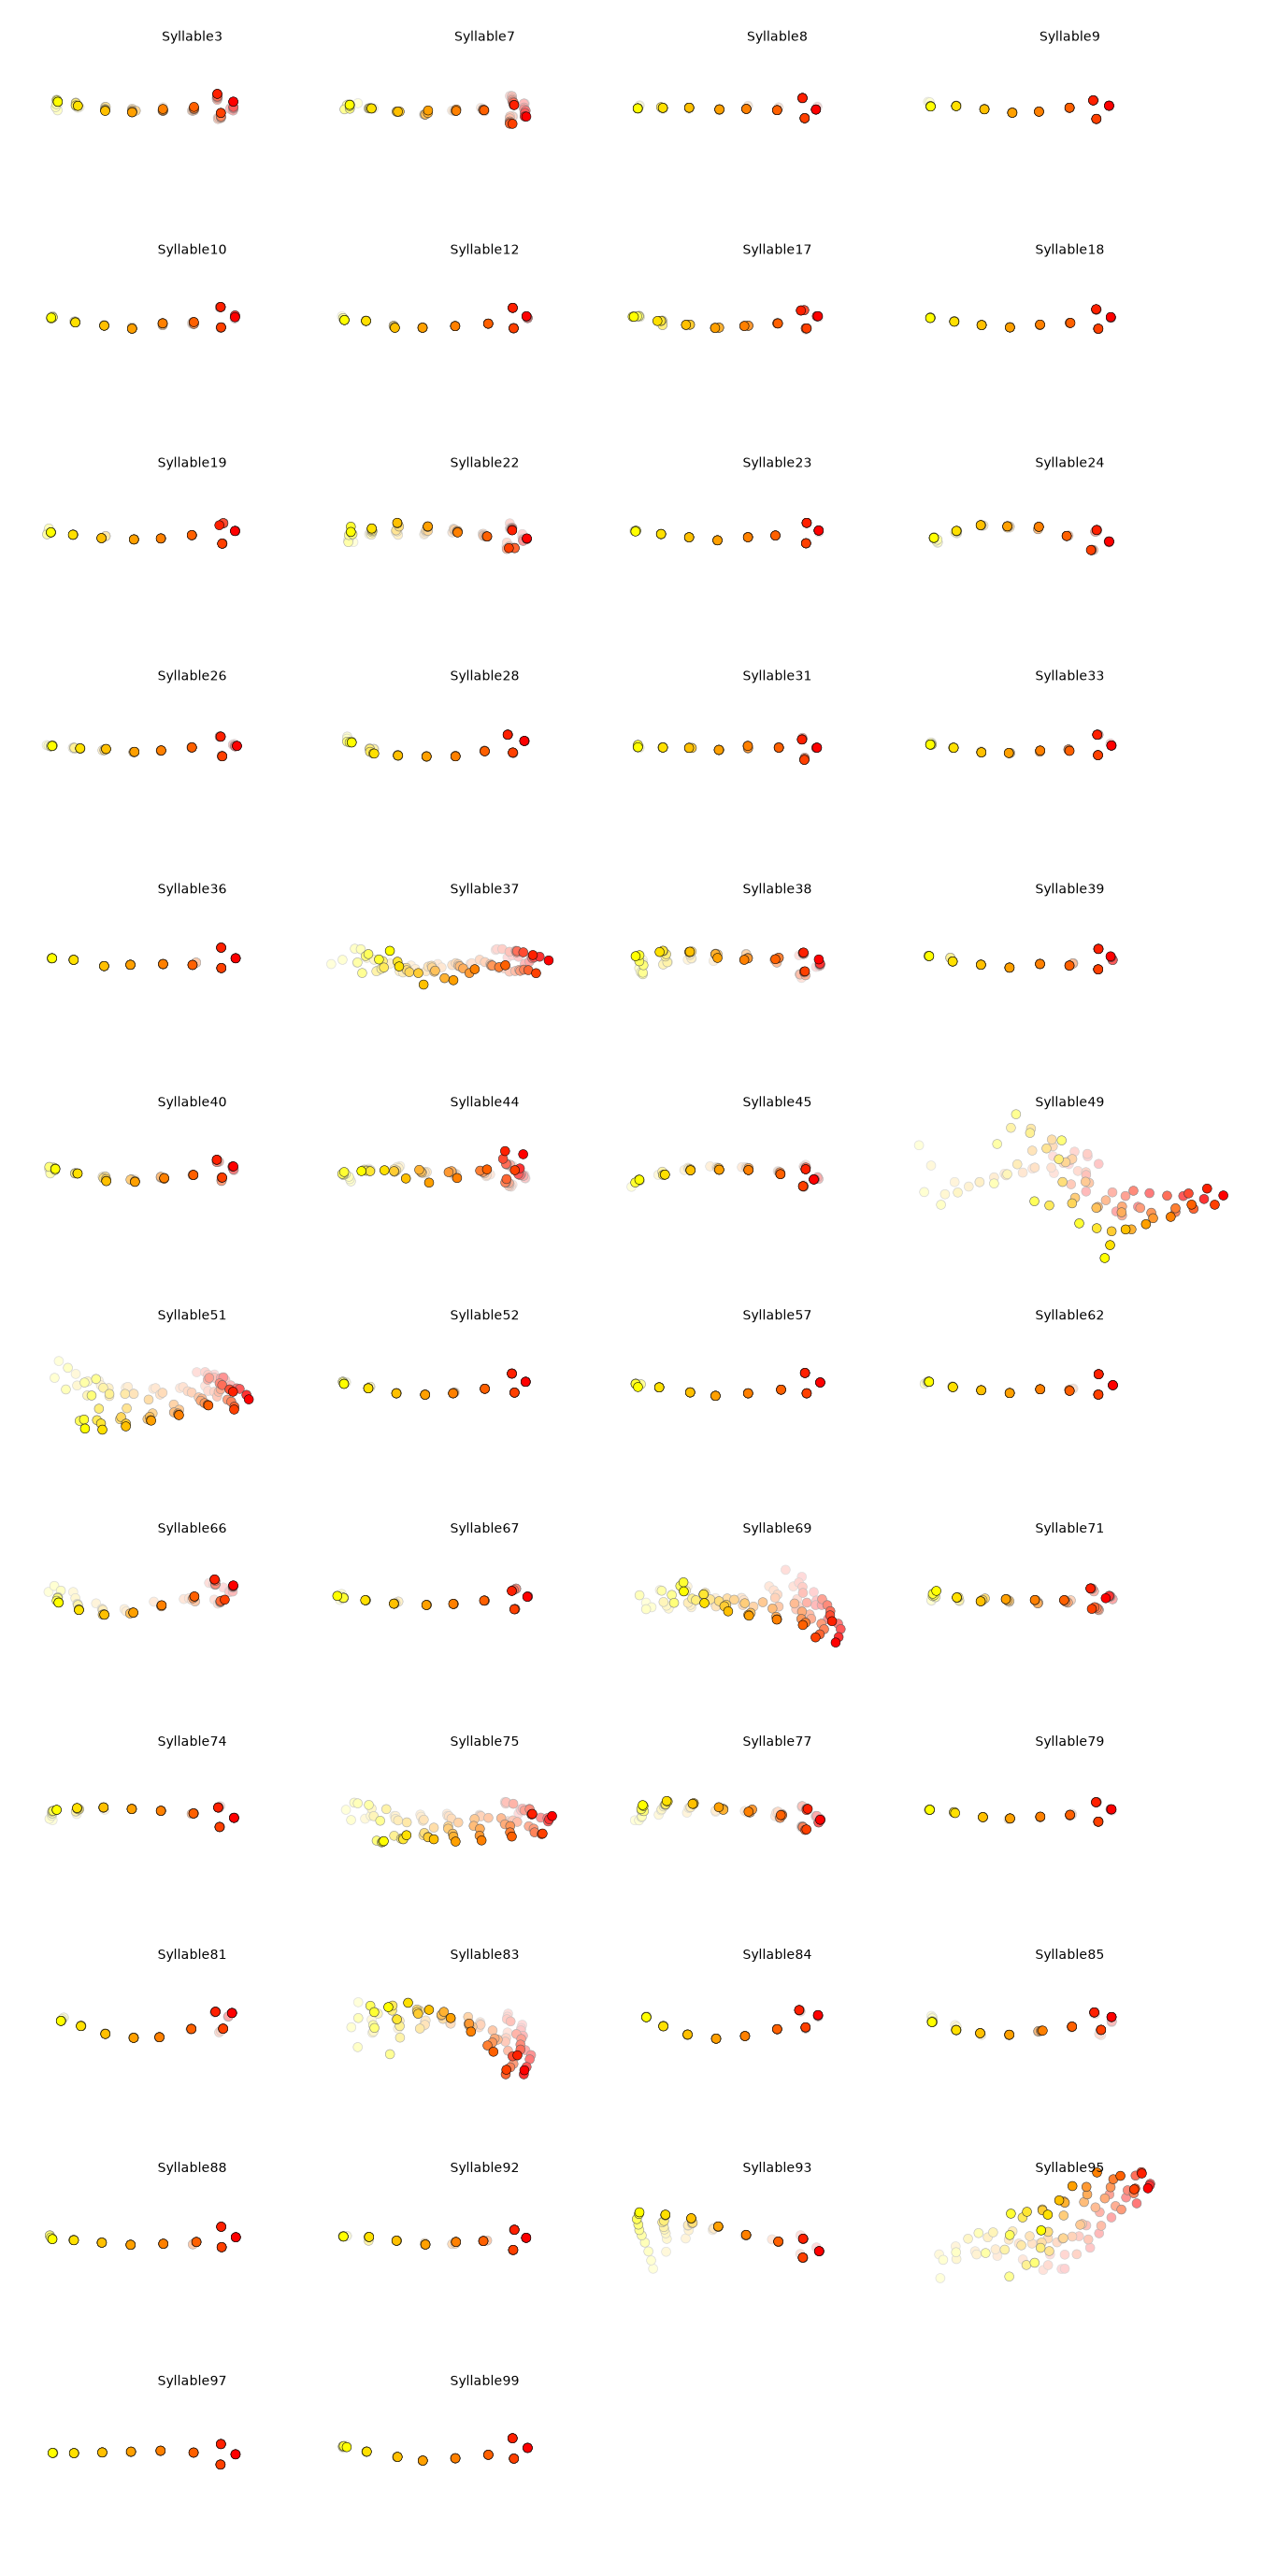

In [284]:
kpms.generate_trajectory_plots(coordinates, results, project_dir, model_name, 
                               fps = 30,
                               before_onset_frames=5, after_onset_frames=15, min_frequency=0.005, min_instance_duration_frames=5, 
                               density_sample=False,
                               #density_sample=True, sampling_options={'n_neighbors': 5},
                               #padding={'bottom': 0.2, 'left': 0.1, 'right': 0.1, 'top': 0.2},
                               )

In [317]:
kpms.plot_similarity_dendrogram(coordinates, results, project_dir, model_name, **config())

ValueError: Distance matrix 'X' must be symmetric.

In [195]:
#kpms.get_typical_trajectories(coordinates, #results, before_onset_frames=5, after_onset_frames=15, min_frequency=0.000005, min_instance_duration_frames=3, bodyparts=None, use_bodyparts=None, density_sample=True, sampling_options={'n_neighbors': 50})

In [312]:
kpms.generate_grid_movies(results, project_dir, model_name, coordinates=coordinates, min_instance_duration_sec = 3/30, min_frequency=0.005, 
                          before_onset_frames=5/30, after_onset_frames=15/30,
                          **config())

Writing grid movies to /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11_03-16_20_04/grid_movies


Checking videos: 100%|████████████████████| 1/1 [00:00<00:00, 21.39it/s]


Using window size of 176 pixels


Generating grid movies: 100%|█████████████| 1/1 [00:01<00:00,  1.94s/it]


{np.int64(18): [('labels.v003_245frames.labeled_trained',
   np.int64(379),
   np.int64(397)),
  ('labels.v003_245frames.labeled_trained', np.int64(1936), np.int64(1972)),
  ('labels.v003_245frames.labeled_trained', np.int64(1293), np.int64(1296)),
  ('labels.v003_245frames.labeled_trained', np.int64(3545), np.int64(3565)),
  ('labels.v003_245frames.labeled_trained', np.int64(334), np.int64(350)),
  ('labels.v003_245frames.labeled_trained', np.int64(2319), np.int64(2342)),
  ('labels.v003_245frames.labeled_trained', np.int64(458), np.int64(464)),
  ('labels.v003_245frames.labeled_trained', np.int64(3582), np.int64(3598)),
  ('labels.v003_245frames.labeled_trained', np.int64(3170), np.int64(3180)),
  ('labels.v003_245frames.labeled_trained', np.int64(2066), np.int64(2089)),
  ('labels.v003_245frames.labeled_trained', np.int64(2852), np.int64(2856)),
  ('labels.v003_245frames.labeled_trained', np.int64(3609), np.int64(3616)),
  ('labels.v003_245frames.labeled_trained', np.int64(2601), np

In [ ]:
#kpms.grid_movie(instances, rows, cols, video_paths, centroids, headings, window_size, video_frame_indexes, dot_color=(255, 255, 255), dot_radius=4, before_onset_frames=30, after_onset_frames=60, scaled_window_size=None, edges=[], overlay_keypoints=False, coordinates=None, plot_options={}, use_dims=None)

Fitting model with kappa=1000.0
Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-1000.0


 49%|█████████████████▏                 | 25/51 [00:01<00:01, 20.39it/s]

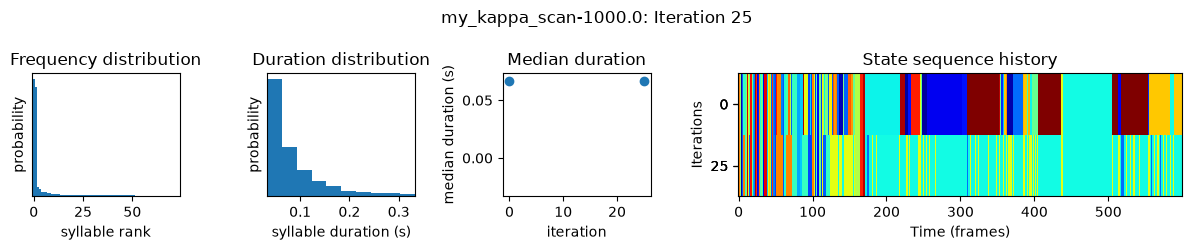

 96%|█████████████████████████████████▋ | 49/51 [00:02<00:00, 19.30it/s]

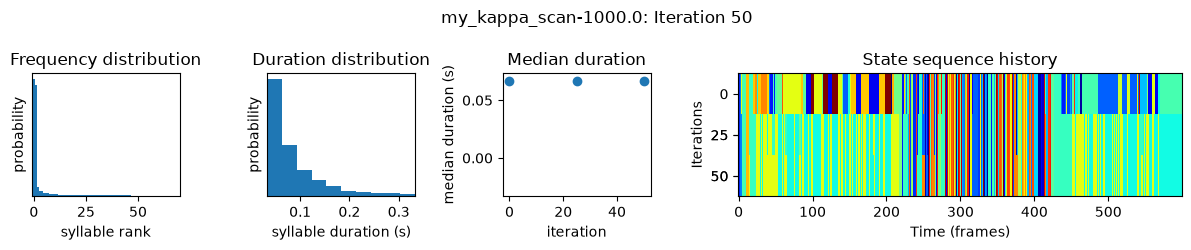

100%|███████████████████████████████████| 51/51 [00:03<00:00, 15.29it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-1000.0


 12%|████▏                             | 25/201 [00:04<00:29,  6.05it/s]

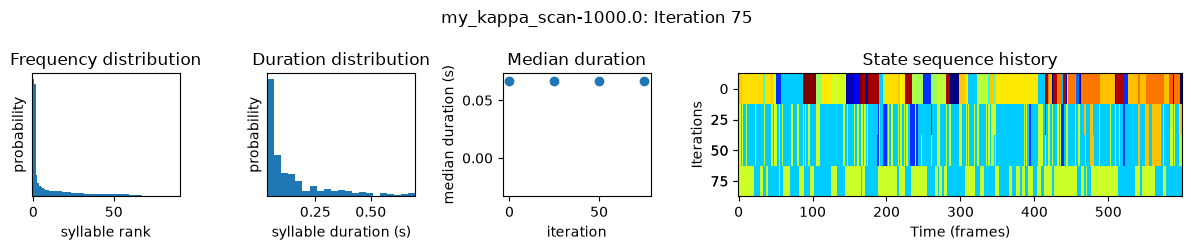

 25%|████████▍                         | 50/201 [00:08<00:25,  5.91it/s]

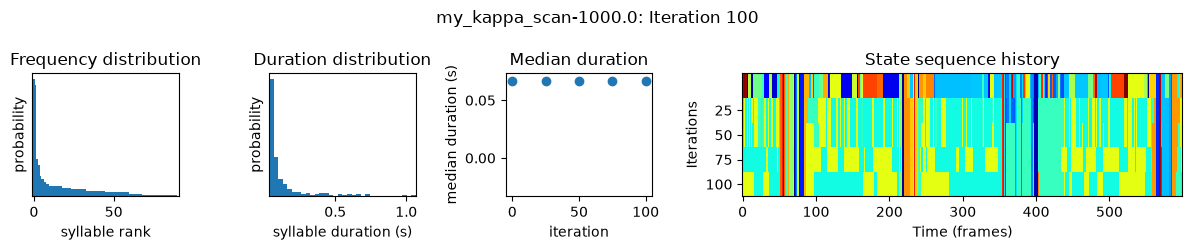

 37%|████████████▋                     | 75/201 [00:13<00:20,  6.06it/s]

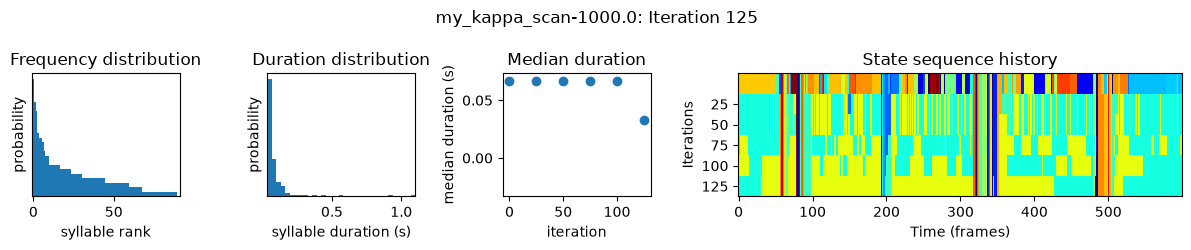

 50%|████████████████▍                | 100/201 [00:18<00:16,  6.13it/s]

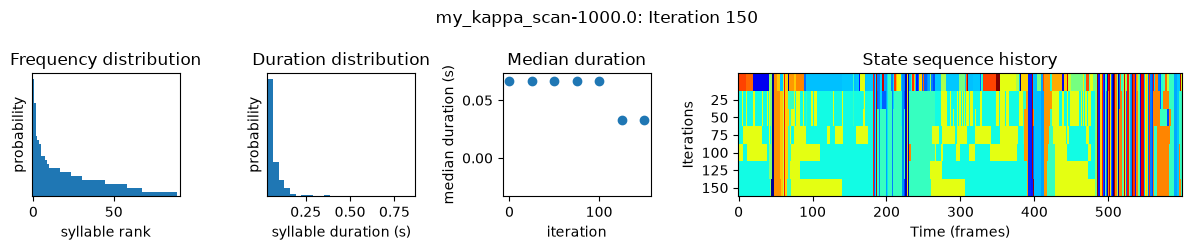

 62%|████████████████████▌            | 125/201 [00:22<00:13,  5.84it/s]

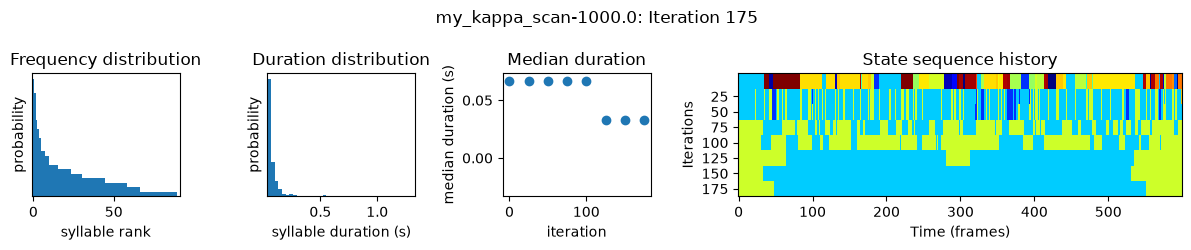

 75%|████████████████████████▋        | 150/201 [00:27<00:08,  6.01it/s]

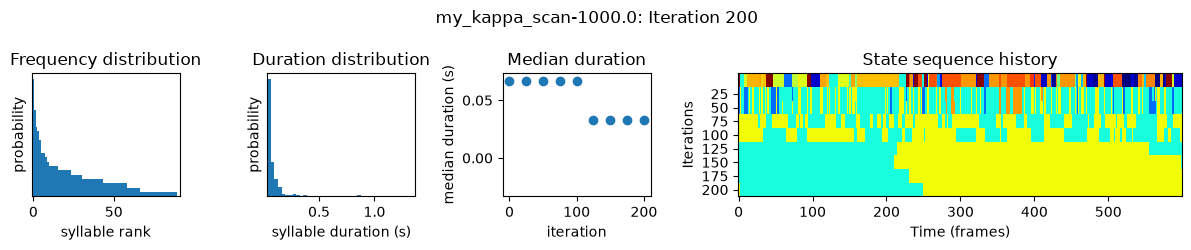

 87%|████████████████████████████▋    | 175/201 [00:32<00:04,  6.03it/s]

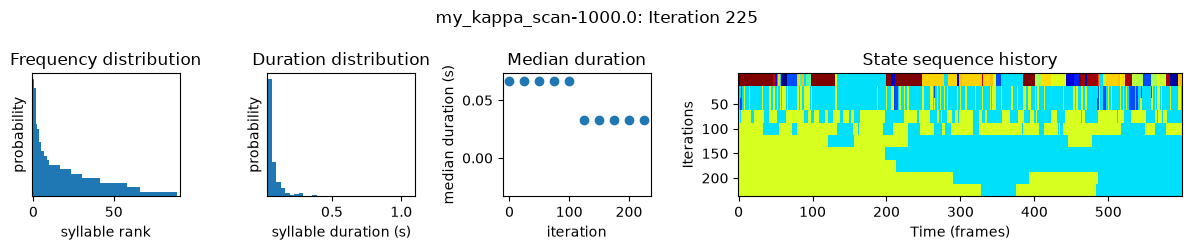

100%|████████████████████████████████▊| 200/201 [00:37<00:00,  6.00it/s]

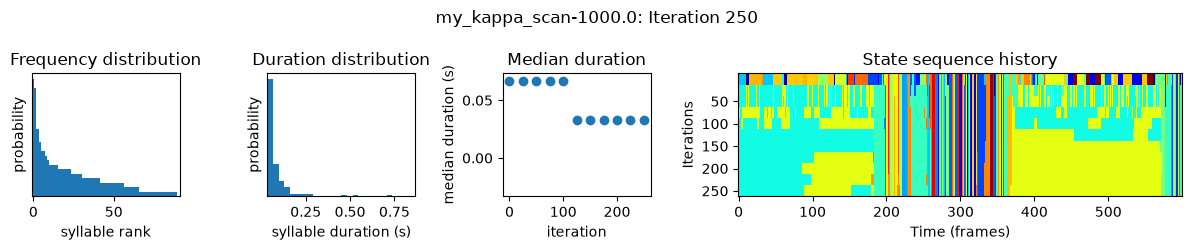

100%|█████████████████████████████████| 201/201 [00:37<00:00,  5.31it/s]


Fitting model with kappa=10000.0
Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-10000.0


 49%|█████████████████▏                 | 25/51 [00:01<00:01, 20.20it/s]

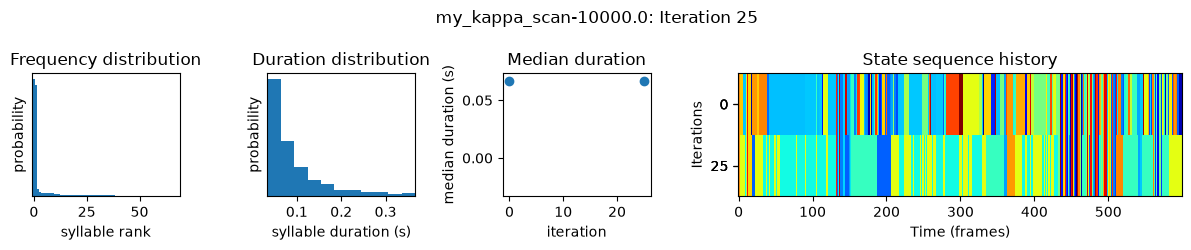

 96%|█████████████████████████████████▋ | 49/51 [00:02<00:00, 19.50it/s]

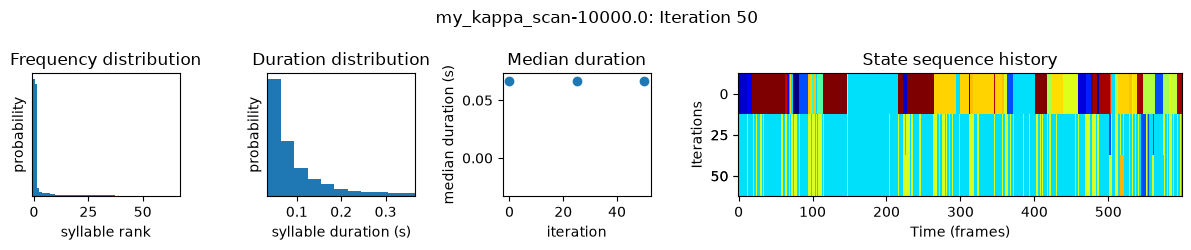

100%|███████████████████████████████████| 51/51 [00:03<00:00, 15.45it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-10000.0


 12%|████▏                             | 25/201 [00:04<00:29,  5.99it/s]

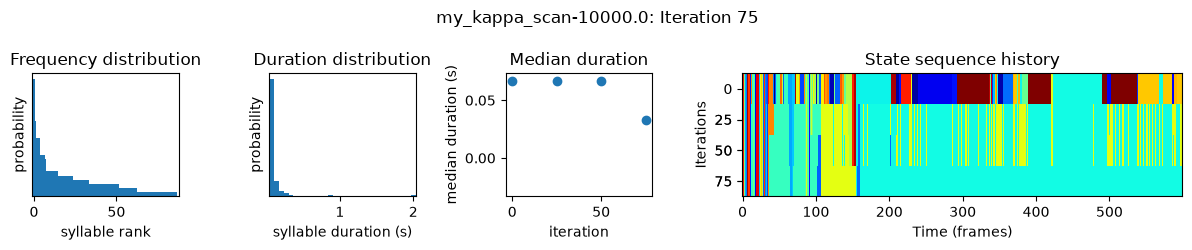

 25%|████████▍                         | 50/201 [00:08<00:25,  5.96it/s]

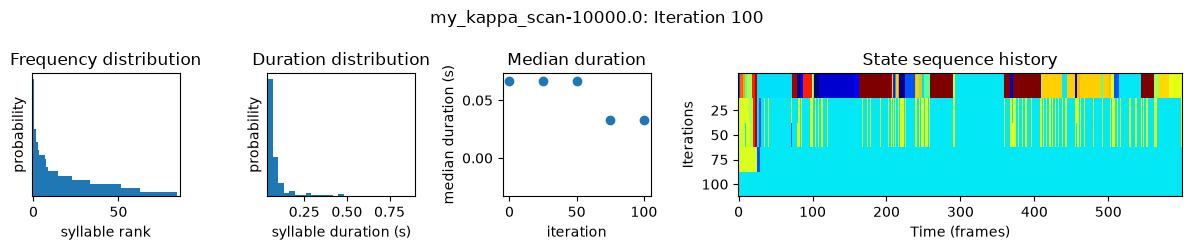

 37%|████████████▋                     | 75/201 [00:13<00:21,  5.93it/s]

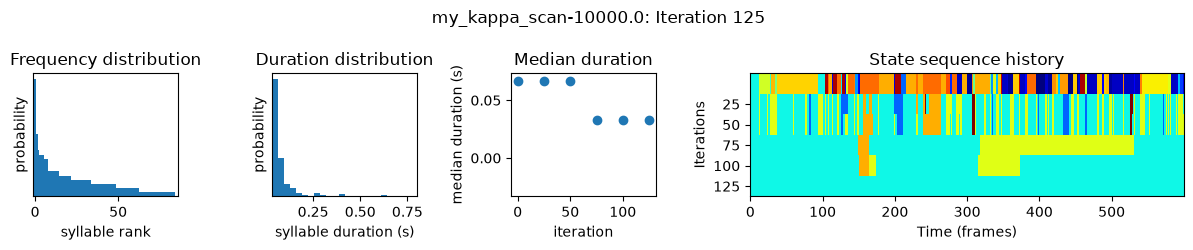

 50%|████████████████▍                | 100/201 [00:18<00:16,  6.06it/s]

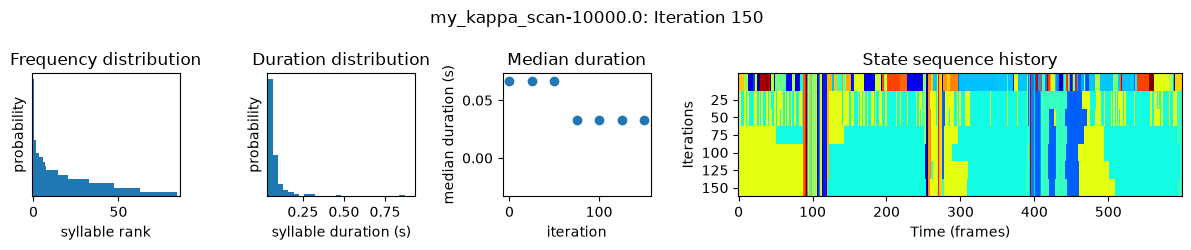

 62%|████████████████████▌            | 125/201 [00:22<00:12,  5.86it/s]

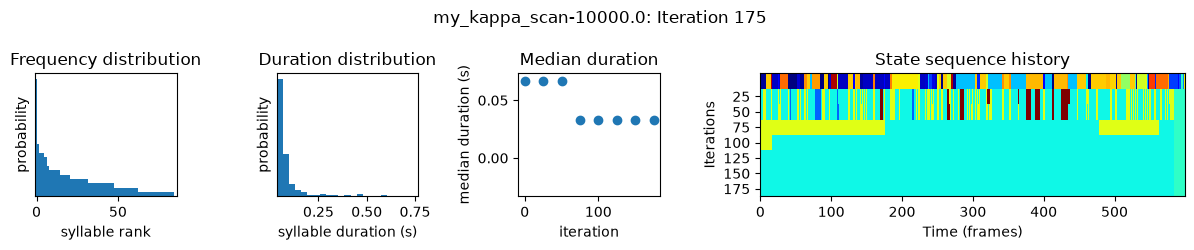

 75%|████████████████████████▋        | 150/201 [00:27<00:08,  6.03it/s]

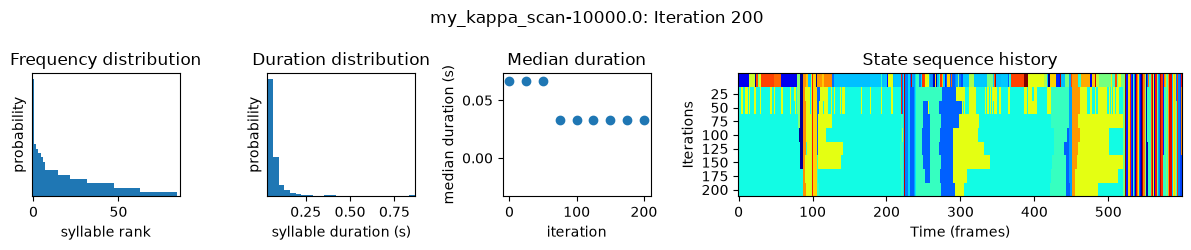

 87%|████████████████████████████▋    | 175/201 [00:32<00:04,  5.99it/s]

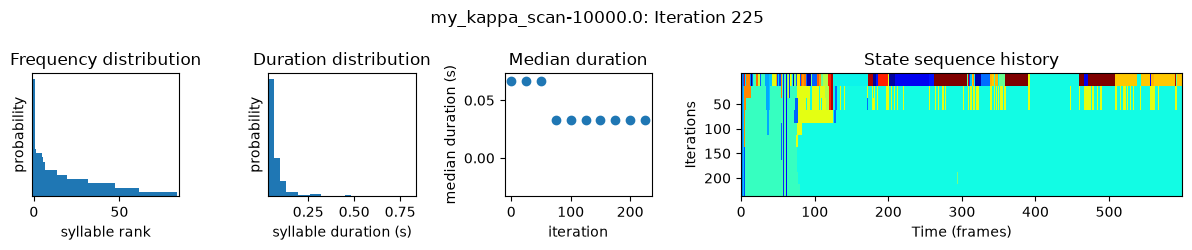

100%|████████████████████████████████▊| 200/201 [00:37<00:00,  6.00it/s]

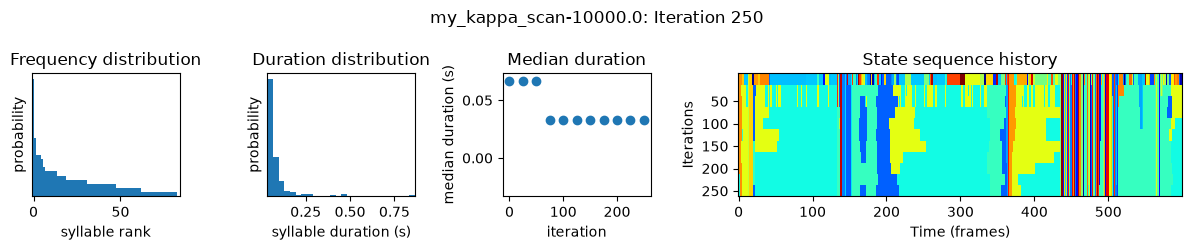

100%|█████████████████████████████████| 201/201 [00:37<00:00,  5.32it/s]


Fitting model with kappa=100000.0
Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-100000.0


 49%|█████████████████▏                 | 25/51 [00:01<00:01, 20.35it/s]

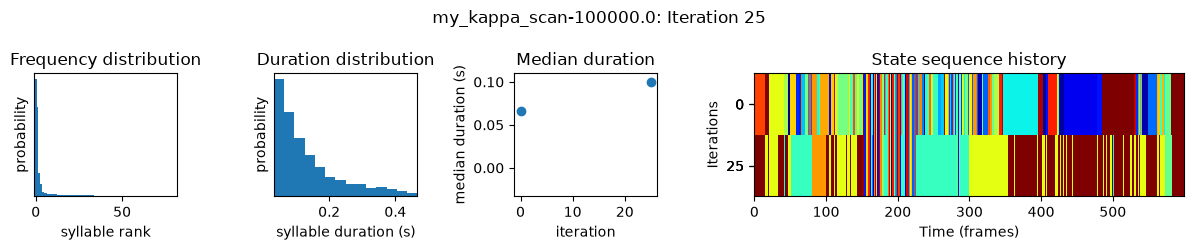

 96%|█████████████████████████████████▋ | 49/51 [00:02<00:00, 19.58it/s]

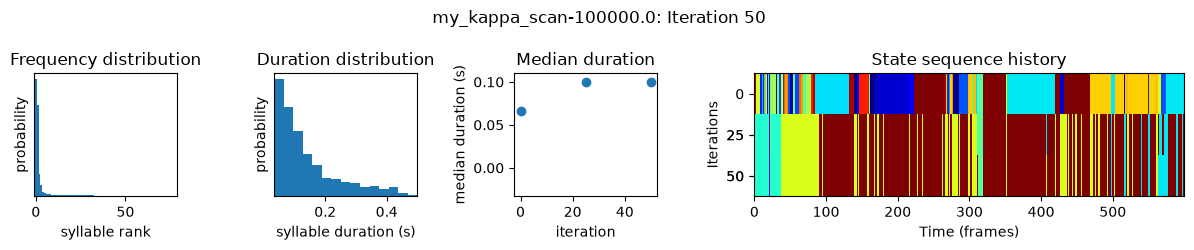

100%|███████████████████████████████████| 51/51 [00:03<00:00, 15.61it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-100000.0


 12%|████▏                             | 25/201 [00:04<00:29,  5.87it/s]

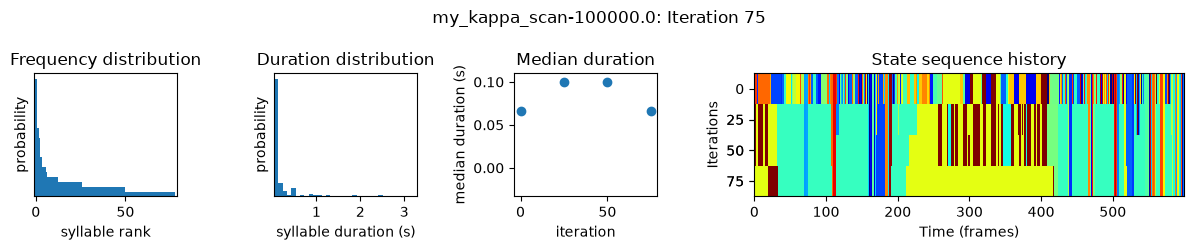

 25%|████████▍                         | 50/201 [00:09<00:26,  5.73it/s]

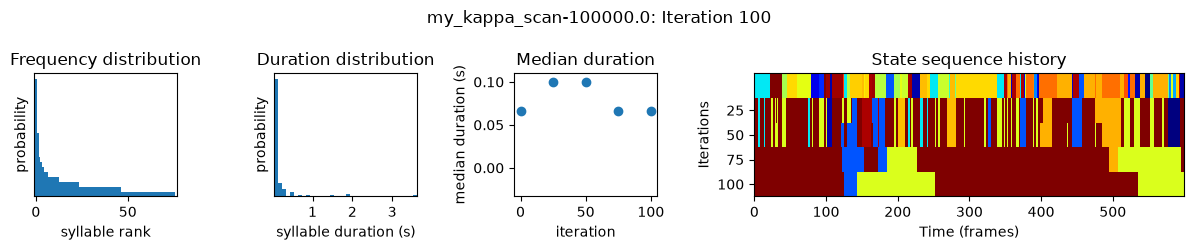

 37%|████████████▋                     | 75/201 [00:13<00:21,  5.76it/s]

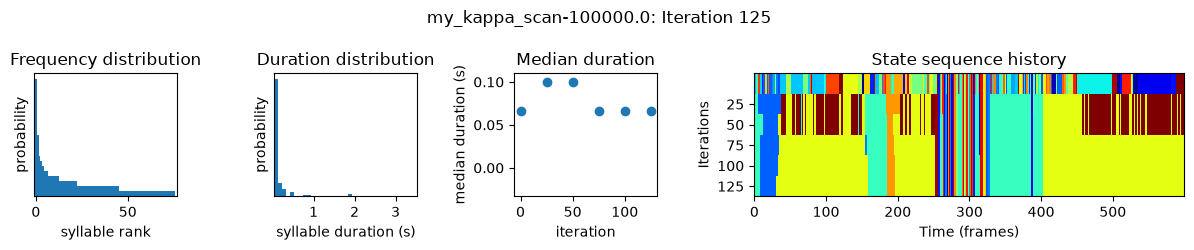

 50%|████████████████▍                | 100/201 [00:18<00:16,  6.05it/s]

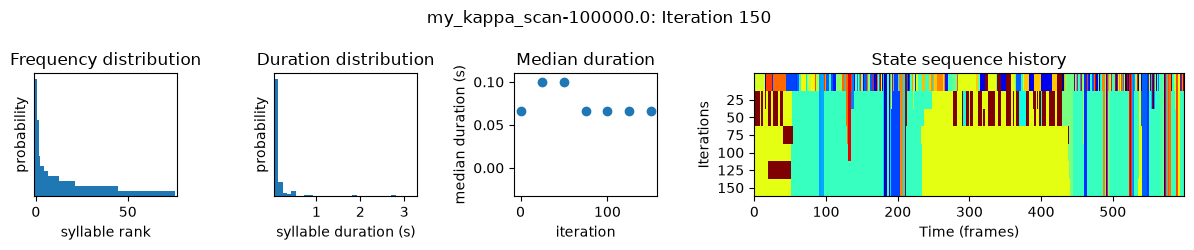

 62%|████████████████████▌            | 125/201 [00:23<00:13,  5.82it/s]

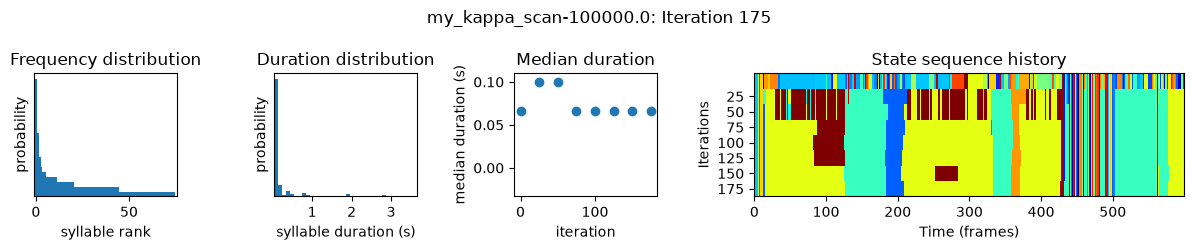

 75%|████████████████████████▋        | 150/201 [00:27<00:08,  5.94it/s]

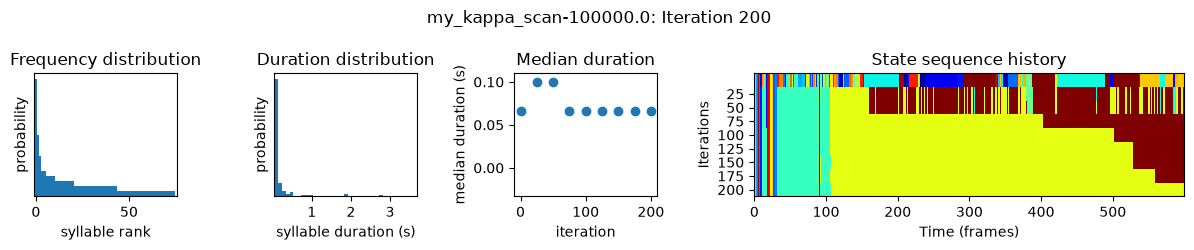

 87%|████████████████████████████▋    | 175/201 [00:32<00:04,  5.95it/s]

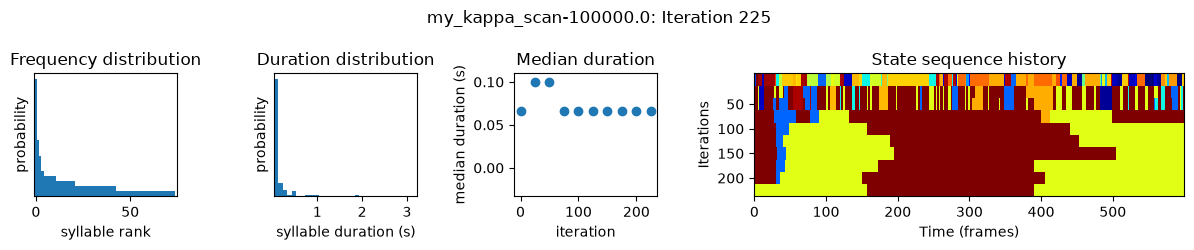

100%|████████████████████████████████▊| 200/201 [00:37<00:00,  5.92it/s]

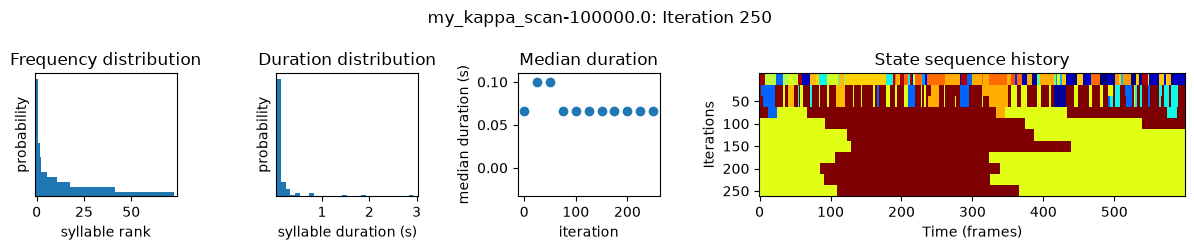

100%|█████████████████████████████████| 201/201 [00:37<00:00,  5.31it/s]


Fitting model with kappa=1000000.0
Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-1000000.0


 49%|█████████████████▏                 | 25/51 [00:01<00:01, 20.30it/s]

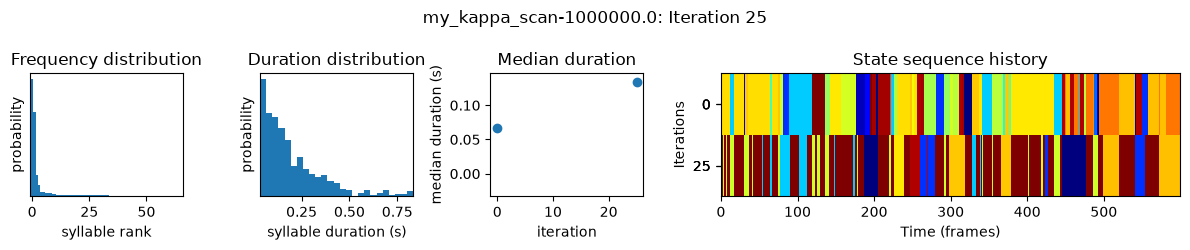

 98%|██████████████████████████████████▎| 50/51 [00:02<00:00, 19.42it/s]

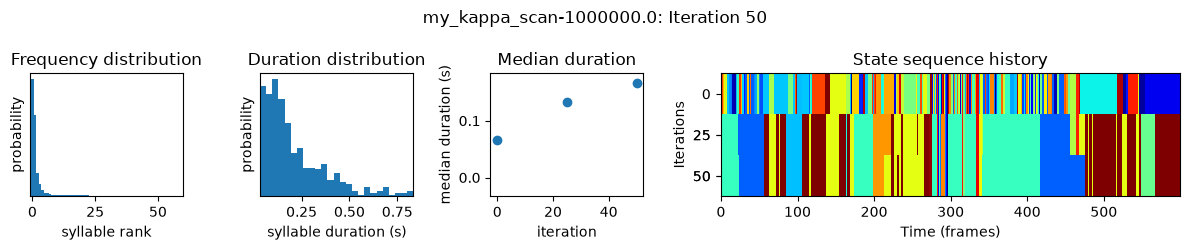

100%|███████████████████████████████████| 51/51 [00:03<00:00, 13.58it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-1000000.0


 12%|████▏                             | 25/201 [00:04<00:29,  5.97it/s]

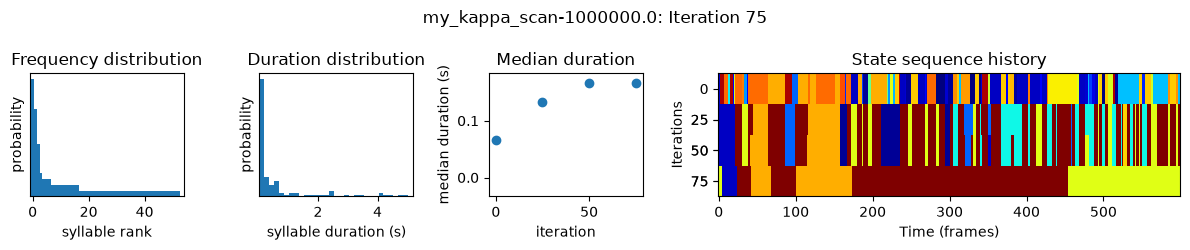

 25%|████████▍                         | 50/201 [00:08<00:25,  5.82it/s]

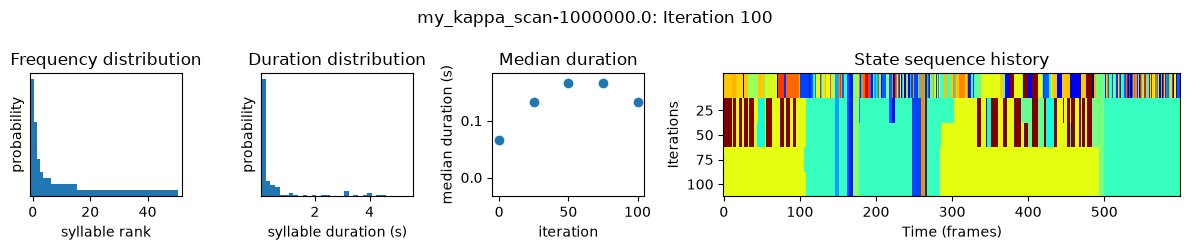

 37%|████████████▋                     | 75/201 [00:13<00:21,  5.93it/s]

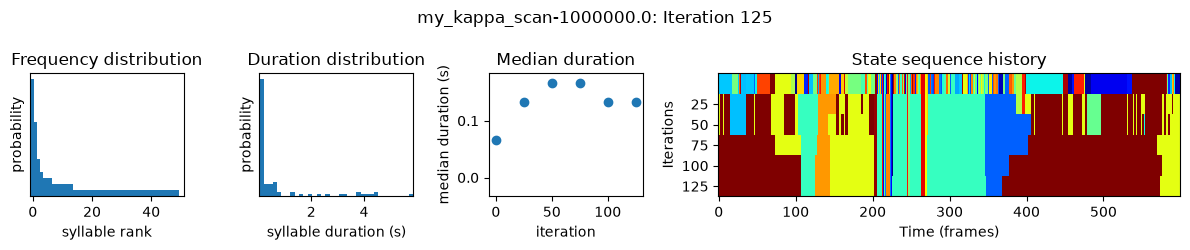

 50%|████████████████▍                | 100/201 [00:18<00:16,  6.06it/s]

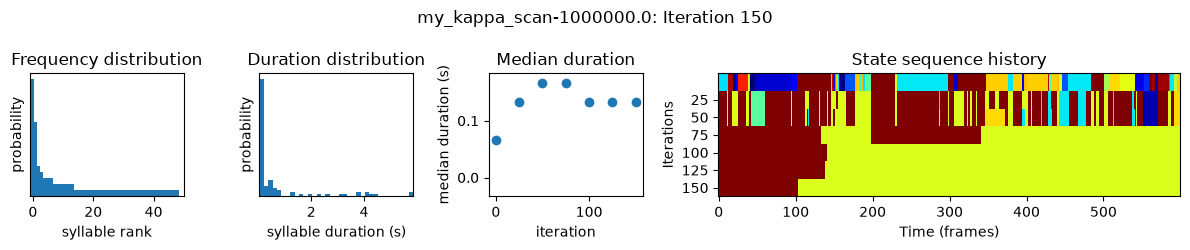

 62%|████████████████████▌            | 125/201 [00:23<00:13,  5.82it/s]

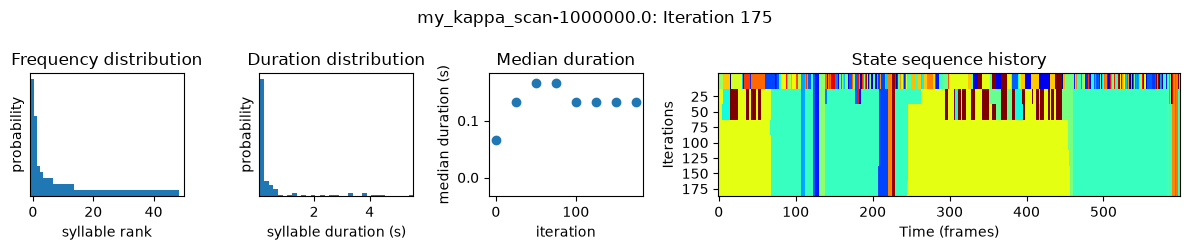

 75%|████████████████████████▋        | 150/201 [00:27<00:08,  5.82it/s]

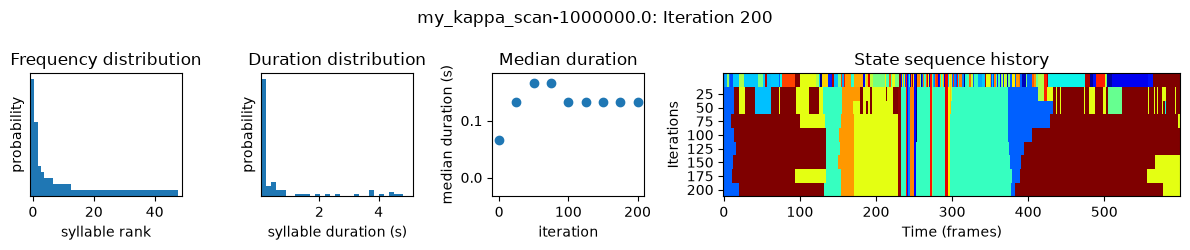

 87%|████████████████████████████▋    | 175/201 [00:32<00:04,  5.86it/s]

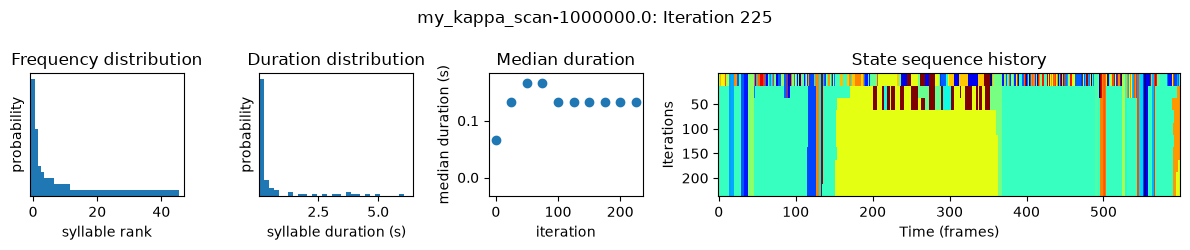

100%|████████████████████████████████▊| 200/201 [00:37<00:00,  5.82it/s]

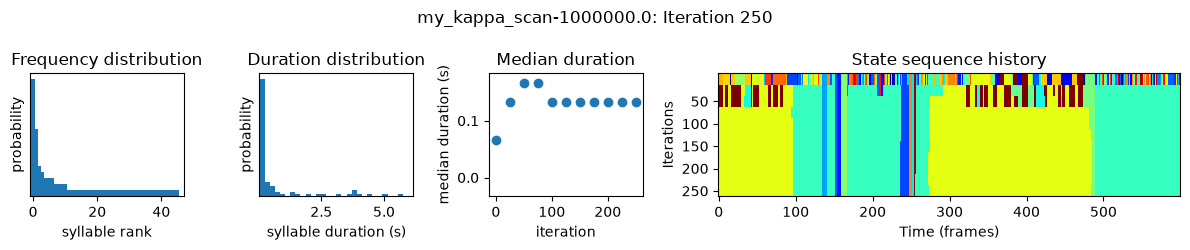

100%|█████████████████████████████████| 201/201 [00:37<00:00,  5.30it/s]


Fitting model with kappa=10000000.0
Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-10000000.0


 49%|█████████████████▏                 | 25/51 [00:01<00:01, 20.45it/s]

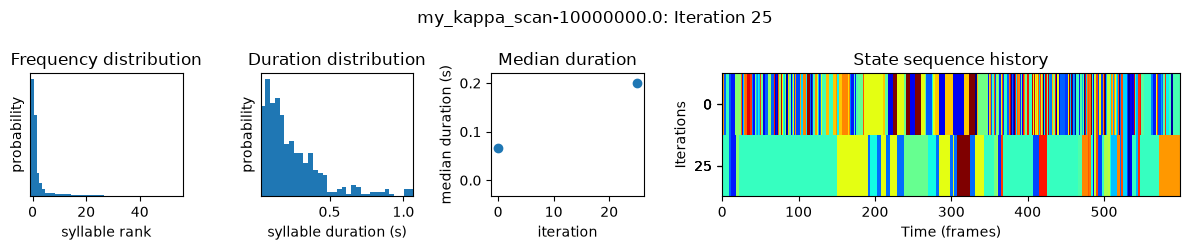

 96%|█████████████████████████████████▋ | 49/51 [00:02<00:00, 19.08it/s]

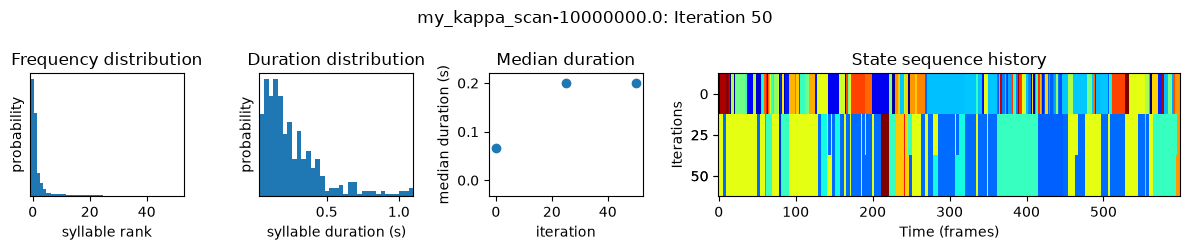

100%|███████████████████████████████████| 51/51 [00:03<00:00, 15.02it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-10000000.0


 12%|████▏                             | 25/201 [00:04<00:29,  5.93it/s]

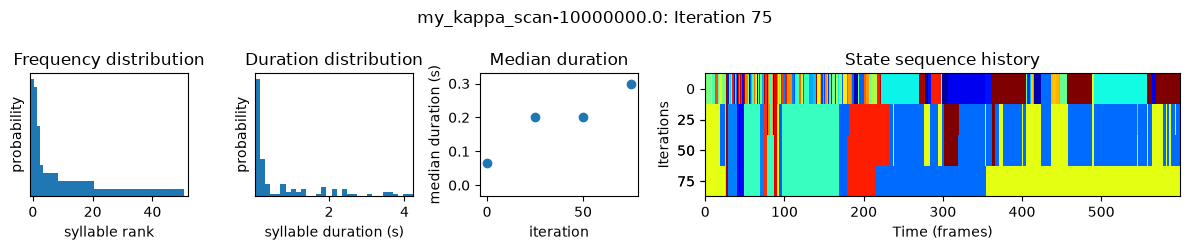

 25%|████████▍                         | 50/201 [00:08<00:25,  5.98it/s]

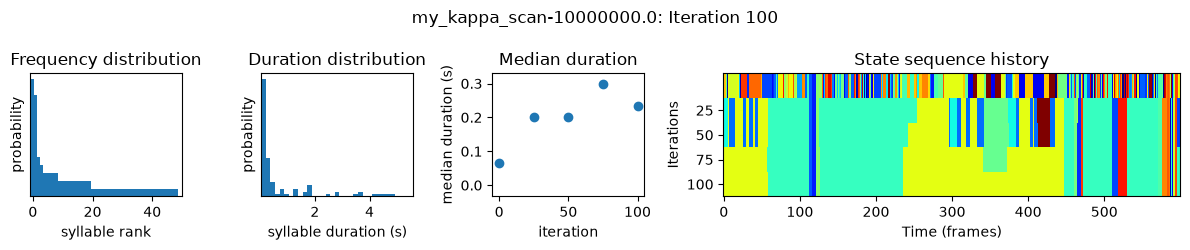

 37%|████████████▋                     | 75/201 [00:13<00:20,  6.02it/s]

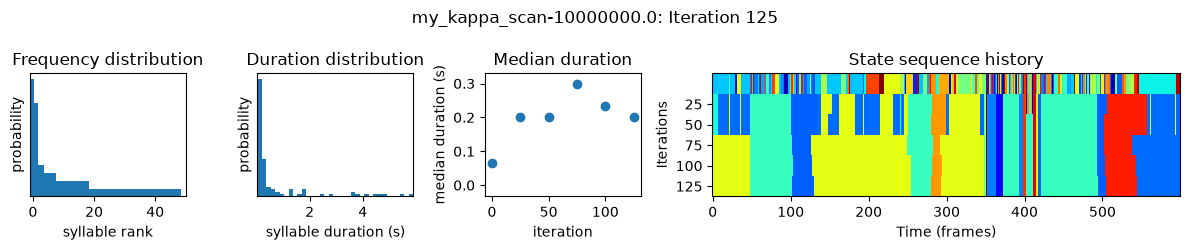

 50%|████████████████▍                | 100/201 [00:18<00:16,  6.14it/s]

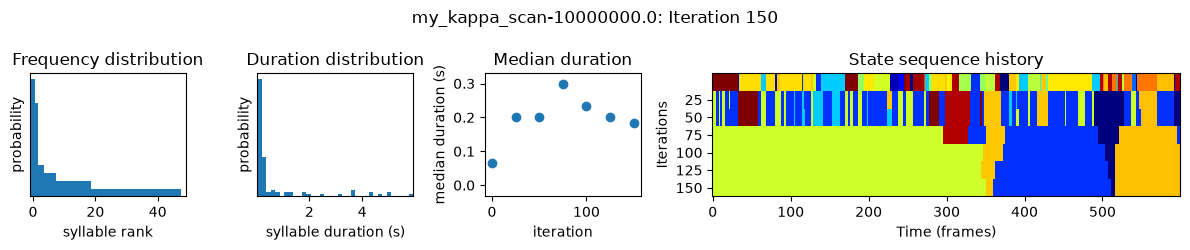

 62%|████████████████████▌            | 125/201 [00:22<00:12,  5.93it/s]

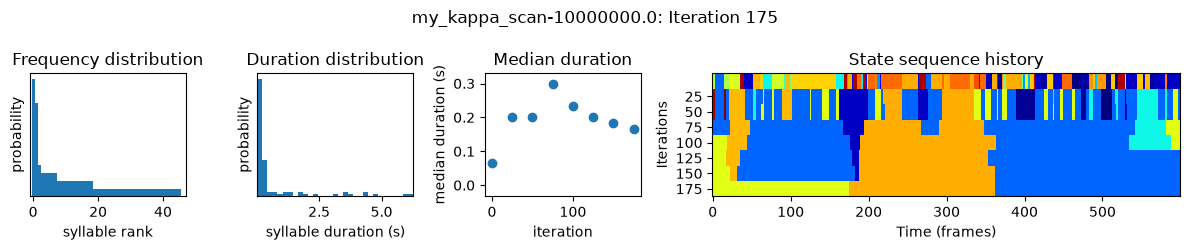

 75%|████████████████████████▋        | 150/201 [00:27<00:08,  6.01it/s]

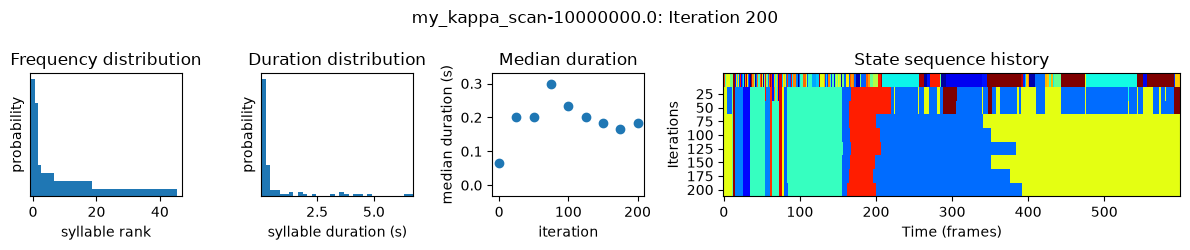

 87%|████████████████████████████▋    | 175/201 [00:32<00:04,  5.99it/s]

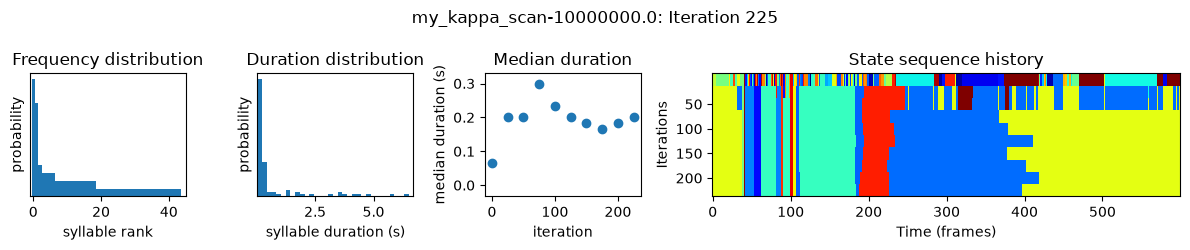

100%|████████████████████████████████▊| 200/201 [00:37<00:00,  5.96it/s]

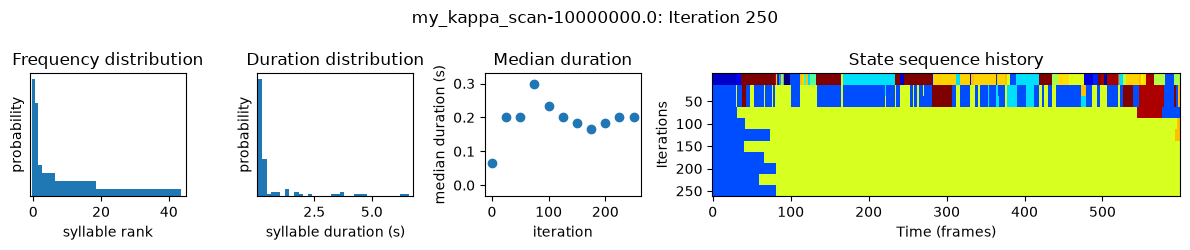

Loading checkpoints: 100%|█████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  5.13it/s]


(<Figure size 800x250 with 2 Axes>, array([1., 1., 2., 4., 6.]))

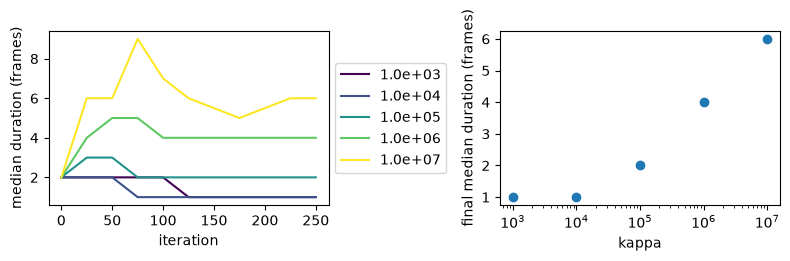

In [129]:
## Automatic kappa scan
import numpy as np

kappas = np.logspace(3,7,5)
decrease_kappa_factor = 10
num_ar_iters = 50
num_full_iters = 200

prefix = 'my_kappa_scan'

for kappa in kappas:
    print(f"Fitting model with kappa={kappa}")
    model_name = f'{prefix}-{kappa}'
    model = kpms.init_model(data, metadata=metadata, pca=pca, **config())

    # stage 1: fit the model with AR only
    model = kpms.update_hypparams(model, kappa=kappa)
    model = kpms.fit_model(
        model,
        data,
        metadata,
        project_dir,
        model_name,
        ar_only=True,
        num_iters=num_ar_iters,
        save_every_n_iters=25,
        **config()
    )[0];

    # stage 2: fit the full model
    model = kpms.update_hypparams(model, kappa=kappa/decrease_kappa_factor)
    kpms.fit_model(
        model,
        data,
        metadata,
        project_dir,
        model_name,
        ar_only=False,
        start_iter=num_ar_iters,
        num_iters=num_ar_iters + num_full_iters,
        save_every_n_iters=25,
        **config()
    );

kpms.plot_kappa_scan(kappas, project_dir, prefix)
